# 07 · The scoreboard

The scoreboard takes the solved run tree of chapters 01–05 and the toy's ground truth and returns every stage's estimate scored against it; it is the one place in the tutorial that may know the truth, and nothing the pipeline uses comes from it.

In [1]:
from pathlib import Path
import json
import logging

import numpy as np
import pandas as pd
from IPython.display import Image, display

from pysuto.tutorial import toy
from pysuto.registry import ImputationRunRegistry, OptimRunRegistry, UncPropRunRegistry

RUNS = Path("runs")
pd.set_option("display.float_format", "{:.3f}".format)
logging.disable(logging.INFO)

Chapters 00–06 never looked at the truth. This chapter runs nothing new: it reads the runs they left in `runs/` and scores them. The toy departs from copper in one way that matters here: copper has no ground truth, ever. Everything below is a luxury of a synthetic case, which is why it lives in `pysuto.tutorial.toy` and `pysuto.diag.truth` and not in the pipeline.

## The seal is lifted

Chapter 00 told you one of the three sources carries one deliberate error. `truth()` returns the world the feeds were drawn from: every edge, both valuations, every year, perfectly balanced. `reveal()` names the error.

In [2]:
ground_truth = toy.truth()
print(ground_truth.shape)
ground_truth.head(4)

(420, 9)


,time,valuation,from_region,from_sector,from_entity,to_region,to_sector,to_entity,value
0,2001,Gross,Montara,Deposit,SB,Montara,Mining,Process,940.434
1,2001,Content,Montara,Deposit,SB,Montara,Mining,Process,9.404
2,2001,Gross,Montara,Mining,Process,Montara,Ore,Flow,940.434
3,2001,Content,Montara,Mining,Process,Montara,Ore,Flow,9.404


The truth is a tidy table like the PSUT, not an array: one row per edge, valuation and year. The six PSUT blocks of chapter 06 are cuts of it, drawn before any noise. Now the reveal:

In [3]:
planted = toy.reveal()
for key, value in planted.items():
    print(f"{key:>12}: {value}")

        feed: customs
 from_sector: Concentrate
 from_region: Montara
   to_sector: Smelting
   to_region: Portua
        time: 2003
   valuation: Gross
      factor: 1000.0
       story: a gross mass booked in t where the feed reports kt: the leg arrives ×1000 (the PNG case of ADR 0033 is kg read as t, the same factor)


One feed (`customs`), one edge (Montara's concentrate to Portua's smelter in 2003, gross mass), booked a factor 1000 too large. The story is the real one, and we come back to it below: kilograms booked where the feed reports tonnes.

## Scoring every stage against the truth

`toy.scoreboard` builds a `TruthDiag` from the run tree: the estimate of every edge at four stages (the feeds' values, the aggregate, the imputed prior, the reconciled `a*`), the truth, and the posterior σ from Stage 5. It needs the ids of the imputation, optimiser and posterior runs; each registry knows its latest.

In [4]:
registries = {"imp": (ImputationRunRegistry, "imp"), "opt": (OptimRunRegistry, "opt"), "uncprop": (UncPropRunRegistry, "uncprop")}
run_ids = {key: reg(str(RUNS / "proc" / sub)).latest_by_label(toy.LABEL).run_id for key, (reg, sub) in registries.items()}
board = toy.scoreboard(RUNS, run_ids)
print(run_ids)

{'imp': 'imp_20261123_151853_1994e51a', 'opt': 'opt_20261123_151908_06e888ed', 'uncprop': 'uncprop_20261123_151913_714e8d7c'}


Start with the planted edge alone, one row per stage. Gross mass, `kt`. Its prior σ is also shown: it is the width the solver was allowed to move this edge by.

In [5]:
edge = board.planted[0]
pd.Series({"truth": board.truth[edge], **{stage: est[edge] for stage, est in board.estimates.items()},
           "sigma prior": board.sigma_prior[edge], "sigma posterior": board.sigma_post[edge]}).to_frame(f"kt, {board.edge_labels([edge])[0]}")

,"kt, Concentrate[Montara] → Smelting[Portua] 2003 Gross"
truth,22.729
feed,23824.238
aggregate,23824.238
prior,23824.238
reconciled,23.628
sigma prior,4980.270
sigma posterior,2.087


The feed carries the error, the aggregation and the imputation pass it on untouched (a single-source edge has nothing to aggregate against), and only the reconciliation brings the value back to the order of the truth. The next sections ask how well that holds over all 420 edges.

## Error by stage

The relative error `|estimate − truth| / |truth|` per edge, summarised by stage. A stage's edge count is the number of edges it estimated at all: feeds cover fewer than the prior, and the prior fills the rest.

In [6]:
errors = board.error_by_stage()
errors

,n_edges,median,p90,max
stage,,,,
feed,93,0.060,0.140,1047.207
aggregate,93,0.060,0.140,1047.207
prior,310,0.051,0.123,1047.207
reconciled,310,0.031,0.096,0.292


In [7]:
print(f"median relative error, feeds {errors.loc['feed', 'median']:.3f} → prior {errors.loc['prior', 'median']:.3f} → reconciled {errors.loc['reconciled', 'median']:.3f}")
print(f"largest relative error: feeds {errors.loc['feed', 'max']:.0f}, reconciled {errors.loc['reconciled', 'max']:.3f}")

median relative error, feeds 0.060 → prior 0.051 → reconciled 0.031
largest relative error: feeds 1047, reconciled 0.292


The figures come from `TruthDiag.plot`: it writes three PNGs and returns their paths. The planted edge is the red dot.

['truth_error_by_stage.png', 'truth_calibration.png', 'truth_residual_rank.png']


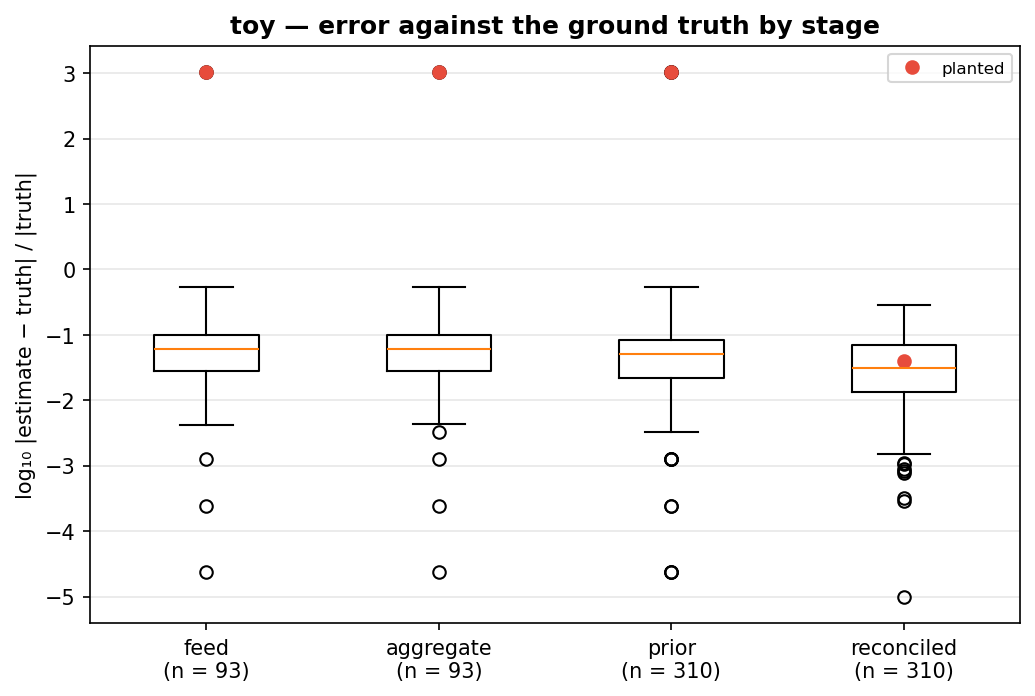

In [8]:
paths = board.plot(str(RUNS / "figs"), show=False)
print([Path(p).name for p in paths])
Image(filename=paths[0])

The log axis makes the point: the planted edge sits three orders of magnitude above everything else through the feed, aggregate and prior stages, and lands inside the box at the end. Reconciliation does not know the truth; it only knows that the balances around this leg and the other sources contradict this one number.

## Calibration and coverage

Stage 5 gave each edge a posterior σ. Is it honest? Two questions answer it: the standardised error `z = (a* − truth) / σ_a*` should look like N(0, 1), and a 95 % interval `a* ± 1.96 σ` should hold the truth about 95 % of the time.

coverage of the 95 % interval: 0.943 of 420 edges; z mean -0.123, sd 1.046


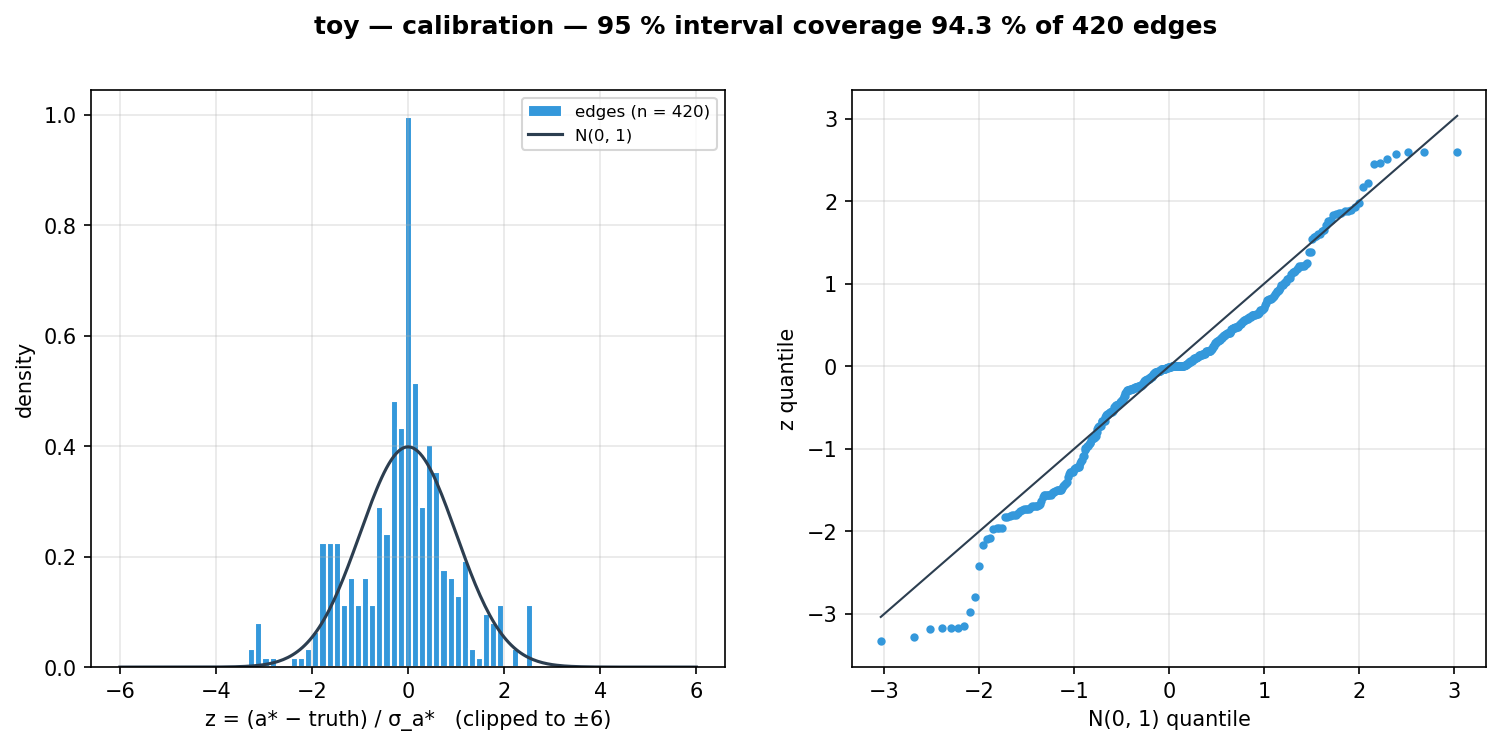

In [9]:
z = board.z_post()
z = z[np.isfinite(z)]
print(f"coverage of the 95 % interval: {board.coverage():.3f} of {board.truth.size} edges; z mean {z.mean():+.3f}, sd {z.std():.3f}")
Image(filename=paths[1])

Read the figure honestly. Coverage is close to the nominal level and the tails are not wild, but the middle of the histogram is taller and narrower than N(0, 1): many flows are pinned by hard balances and sit almost exactly at the truth. One toy, one seed, five years: this is a reading, not a proof of calibration. Copper's calibration uses a different protocol (manuscript §3.3).

## The residual rank, with the planted leg marked

`prior_z` is the solver's own price of moving an edge from the prior to `a*`: `z = (a* − a_prior) / σ_a`. It needs no truth. `TruthDiag` ranks every edge by it and marks the planted ones.

In [10]:
rank = board.residual_rank()
rank.head(6)

,edge_id,edge,z,planted
0,194,Concentrate[Montara] → Smelting[Portua] 2003 G...,-4.779,True
1,195,Concentrate[Montara] → Smelting[Portua] 2003 C...,-4.031,False
2,389,Metal[Portua] → Use[Portua] 2005 Content,1.711,False
3,388,Metal[Portua] → Use[Portua] 2005 Gross,1.646,False
4,407,Metal[Isla] → Use[Isla] 2004 Content,1.555,False
5,406,Metal[Isla] → Use[Isla] 2004 Gross,1.514,False


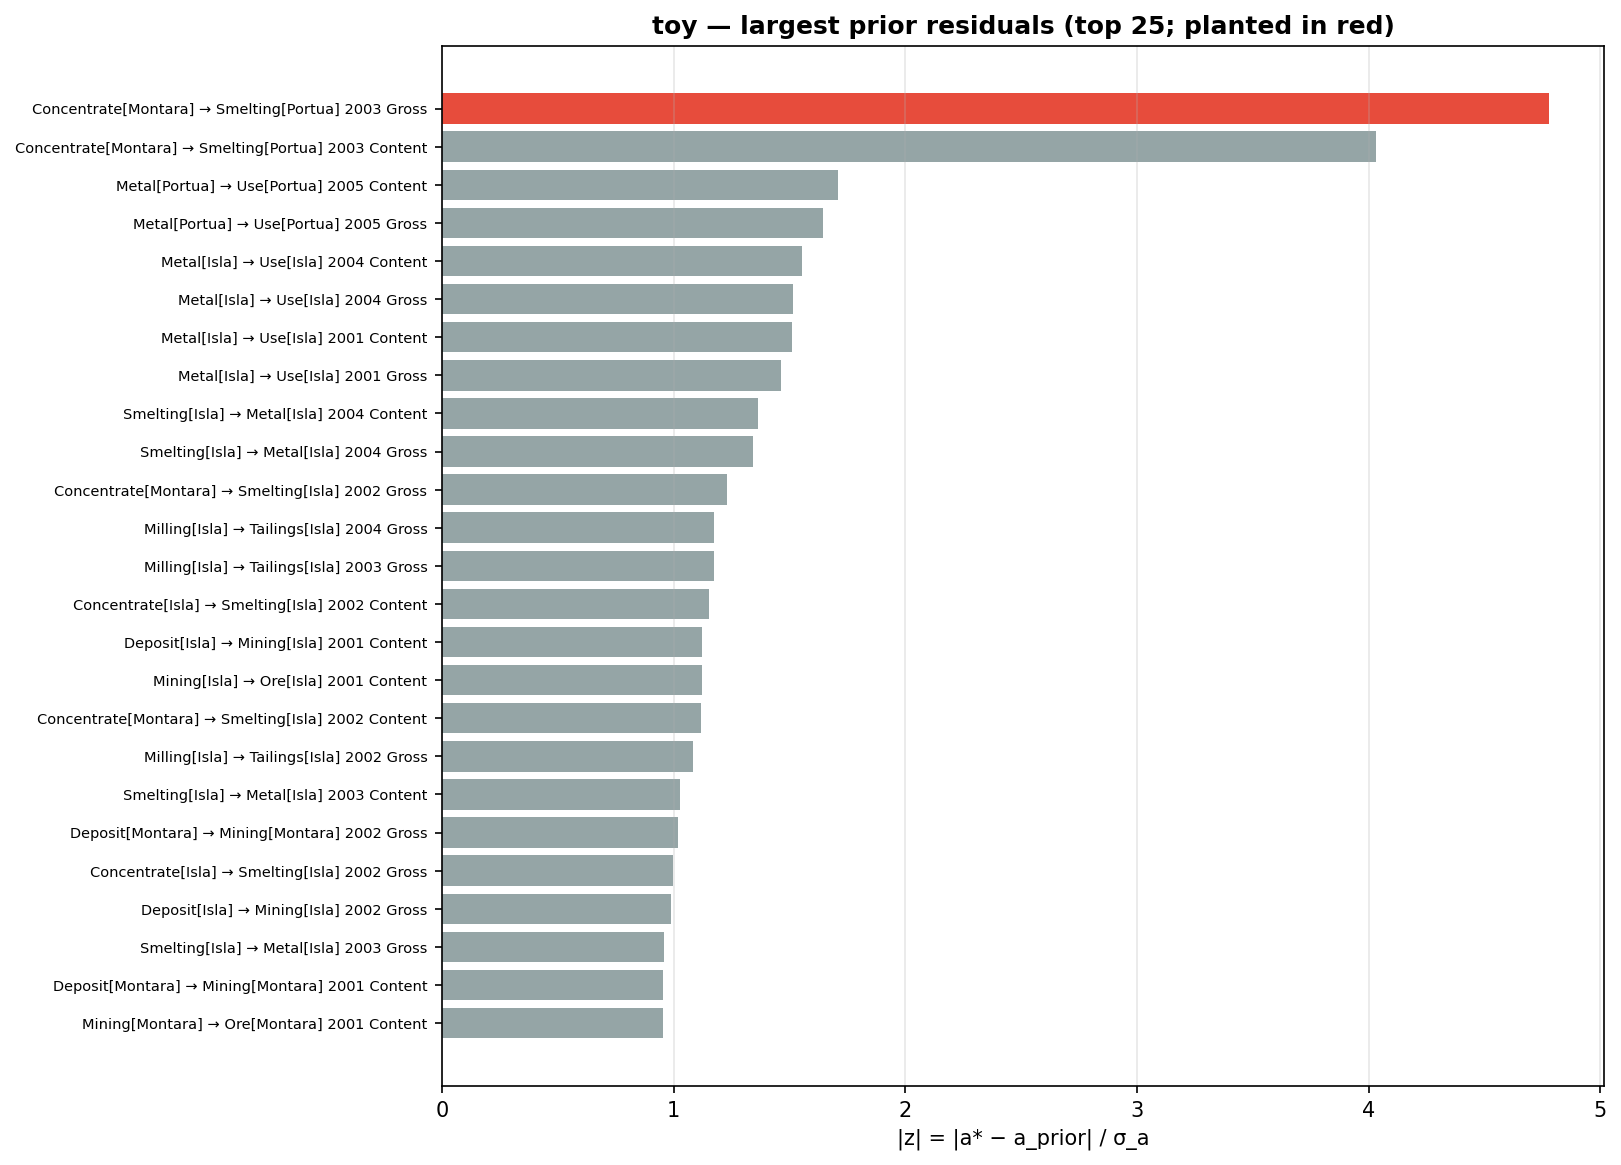

In [11]:
Image(filename=paths[2])

The planted leg is first. Its twin in the `Content` valuation is second: Stage 2's trade-twin imputer (`trade`, chapter 02) derived the content leg's prior from the gross one with the concentrate grade, so it inherits the error. Then there is a gap, and a field of edges below |z| = 2 that no one would look at twice.

## Retention by category, prior against truth

Retention is `Σa*/Σa_prior` by category and year (GLOSSARY). It says how much of the prior the posterior kept, and in the toy we can set it beside `prior/truth` and `a*/truth`. One year, all categories, `kt Content`:

In [12]:
retention = board.retention("Content")
retention[["prior/truth", "a*/truth", "retention"]].xs("2003", level="year")

,prior/truth,a*/truth,retention
category,,,
Concentrate → Smelting,557.604,0.932,0.002
Deposit → Mining,0.984,0.932,0.947
Metal → Use,0.924,0.956,1.035
Milling → Concentrate,0.994,0.932,0.938
Milling → Tailings,0.994,0.932,0.938
Mining → Ore,0.984,0.932,0.947
Mining → WasteRock,NaN,NaN,NaN
Ore → Milling,0.994,0.932,0.938
Scrap → Smelting,1.028,1.028,1.001


One category stands out: `Concentrate → Smelting`, whose prior is wildly above the truth. Every other category has a prior within about 10 % of the truth and a retention near 1. (`Mining → WasteRock` is empty in `Content`: waste rock carries no orium.) The same category in every year:

In [13]:
retention.loc["Concentrate → Smelting", ["truth [kt Content]", "prior [kt Content]", "a* [kt Content]", "retention"]]

,truth [kt Content],prior [kt Content],a* [kt Content],retention
year,,,,
2001,11.199,12.396,11.930,0.962
2002,11.592,10.952,11.196,1.022
2003,11.973,6675.978,11.156,0.002
2004,12.330,12.692,12.103,0.954
2005,12.358,13.426,12.868,0.958


Retention of `Concentrate → Smelting` in 2003 is far below 1. That is not a failure of the solver: it removed nearly all of a prior that the truth says was wrong, and `a*/truth` in the table above is about as close to 1 as in every other category of 2003. A low retention is a question, not a verdict: here the truth answers it. In copper there is no truth, and the same number goes to the manuscript's retention tables with its category and year and nothing else to hold on to.

<details><summary>Going deeper: why a* is not exactly the truth on the planted edge</summary>

The solver minimises the σ-weighted distance to the prior (Eq. 2). The prior on the planted edge is the corrupted feed value with a σ from its pedigree, so the objective prefers to keep it a little, and it is the balances at both ends of the leg and the sources that cover them that pull `a*` down. The posterior σ of Stage 5 (Eq. 3) shrinks accordingly, and the 95 % interval of this edge holds the truth, as the check below shows. What the solver cannot do is recover the truth exactly: it has no way to tell whether the number is wrong or the world has changed.
</details>

In [14]:
print(f"planted edge: a* / truth = {board.estimates['reconciled'][edge] / board.truth[edge]:.3f}; 95 % interval holds the truth: {bool(board.covered()[edge])}")

planted edge: a* / truth = 1.040; 95 % interval holds the truth: True


## The reveal, and the real case

The defect was designed on a real one. In copper's Round Z (ADR 0033, amended) the BACI trade feed booked the concentrate (HS 260300) that Papua New Guinea sent to the Philippines in 2020 as 21,277,530 t at a value of 76,901 kUSD: 3.6 USD per tonne against a copper price of 6,224 USD per tonne. Kilograms were booked as tonnes; the value field was intact and the quantity field was a factor 1000 off. PNG's recorded export mass was 22,248 / 40,813 / 21,607 / 28,381 kt in 2019–2022 against 205–416 kt in 2015–2018. The Mass prior was inflated; the solver shrank it back and kept only 0.584 of the world's concentrate `Mass` prior in 2020 (retention, ADR 0033 amendment, run `opt_20261007_130833_1a9b7af7`). The fix was at the parse, from the value (ADR 0033's amendment).

The toy's planted leg is the same defect at a size you can hold in your head: one leg, one year, a factor 1000. Two things differ, and both are honest limits:

- The toy's Customs feed has no value field, so the copper detector (the value-implied copper fraction) has nothing to read here. The toy is caught the other way, by disagreement with another source.
- In copper the inflated leg also bent the prior of *other* edges, through the trade-share weights that read the mass (ADR 0033). The toy's defect is the minimal version: one leg, one year.

## What the pipeline knew without knowing the truth

Everything above used the truth. The pipeline had none. What did it know? `soft_residuals` lists every soft term of the solved QP as a z-score, using only the run tree.

In [15]:
soft = toy.soft_residuals(RUNS)
top = soft.head(4).assign(edge=lambda d: board.edge_labels(d["edge_id"].astype(int)))
top[["edge", "time", "z"]]

,edge,time,z
0,Concentrate[Montara] → Smelting[Portua] 2003 G...,2003,-4.779
1,Concentrate[Montara] → Smelting[Portua] 2003 C...,2003,-4.031
2,Metal[Portua] → Use[Portua] 2005 Content,2005,1.711
3,Metal[Portua] → Use[Portua] 2005 Gross,2005,1.646


The first row is the planted leg. The pipeline did not know that; it knew that this number was several σ from what everything else implied, and that no other soft term was in its league. Make the claim exact:

In [16]:
print(f"the largest soft residual is the planted edge: {int(soft.iloc[0]['edge_id']) == board.planted[0]}")
print(f"|z| of the largest {abs(soft.iloc[0]['z']):.2f}; of the largest edge that is not one of the two {abs(soft.iloc[2]['z']):.2f}")

the largest soft residual is the planted edge: True
|z| of the largest 4.78; of the largest edge that is not one of the two 1.71


So the pipeline knew three things and did not know three:

- **Knew:** one edge disagrees with the rest by far more than any other; its twin in the other valuation disagrees with it too; reconciliation resolved the disagreement towards the other sources.
- **Did not know:** which of the two valuations carries the defect (both are flagged), whether the feed or the world was wrong, or that the answer is "a factor 1000".
- **Could not fix:** σ cannot repair a data contradiction. The solver moved `a*` as far as the other sources allowed; the input stays wrong until someone reads the feed. That is what the residual rank is for: it is a to-do list for the human, ranked, and the first line of it is the one that matters here.

Chapter 08 goes the other way: it breaks the pipeline on purpose, one assumption at a time.

<details><summary>Going deeper: what a score against the truth cannot tell copper</summary>

Everything on this page measures the pipeline against the world it was fed. A real case has the opposite problem: the truth is unavailable, and what stands in for it is a set of measured alternatives (manuscript Table 2) and a calibration against the sources themselves (manuscript §3.3). The toy shows that the machinery can find a planted defect and report an honest interval. It does not show that copper's σ values are right; for that, nothing in this notebook helps.
</details>

## Where this run came from

The scoreboard reads three runs. Their sidecars hold the chain; here the posterior run's, the one whose σ the calibration used:

In [17]:
sidecar = json.loads((RUNS / "proc" / "uncprop" / run_ids["uncprop"] / "metadata.json").read_text())
print(json.dumps(sidecar["parents"], indent=2))

{
  "inputs": {},
  "upstream": {
    "opt_run_id": "opt_20261123_151908_06e888ed",
    "const_run_id": "const_20261123_151905_b9419350"
  }
}


That is the whole tutorial chain, from the world to the scoreboard. The next chapters leave the happy path.